# Exercise 1 — Trực quan hoá & kiểm chứng bằng mô phỏng

**Thống kê nhiều chiều & cao chiều · Chương 2: Phân phối chuẩn đa biến và lý thuyết mẫu**

Notebook này đi kèm `Exercise1_Solution.tex`. Với mỗi bài, ta làm ba việc:

1. **Nhắc lại kết quả lý thuyết** đã chứng minh trong bản lời giải;
2. **Mô phỏng Monte Carlo** một mẫu rất lớn từ đúng phân phối của đề bài;
3. **Đối chiếu** con số/hình ảnh thực nghiệm với công thức — nếu lý thuyết đúng thì hai bên phải trùng nhau, và chỗ nào *không* trùng chính là chỗ đáng học nhất.

Nguyên tắc xuyên suốt: mọi nhận xét trong notebook đều đọc ra từ output thật ở ngay bên dưới, không viết trước.

In [1]:
set.seed(2026)
suppressPackageStartupMessages({
  library(MASS)      # mvrnorm
  library(mvtnorm)   # rmvnorm, dmvnorm
  library(ggplot2)
  library(dplyr)
  library(tidyr)
  library(patchwork)
})

options(repr.plot.width = 11, repr.plot.height = 4.2, repr.plot.res = 150,
        digits = 4, scipen = 6)

# Giao diện đồ thị tối giản: xám + một màu nhấn, đồng bộ với bản LaTeX
INK  <- "grey20"; ACC <- "#8B1A1A"; ACC2 <- "#1F4E79"; SOFT <- "grey65"

theme_hds <- function(base_size = 12) {
  theme_minimal(base_size = base_size) +
    theme(panel.grid.minor = element_blank(),
          panel.grid.major = element_line(colour = "grey91", linewidth = 0.3),
          plot.title    = element_text(face = "bold", size = rel(0.98)),
          plot.subtitle = element_text(colour = "grey35", size = rel(0.82)),
          axis.title    = element_text(colour = "grey30"),
          legend.position = "bottom",
          legend.title = element_blank())
}
theme_set(theme_hds())

cat("R", paste(R.version$major, R.version$minor, sep = "."), "— sẵn sàng\n")

Warning message:
“package ‘mvtnorm’ was built under R version 4.6.1”


R 4.6.0 — sẵn sàng


## 0. Vài hàm dùng lại

- `conf_ellipse()` — đường bao xác suất $\{x : (x-\mu)'\Sigma^{-1}(x-\mu) = \chi^2_{2,\alpha}\}$ của một phân phối chuẩn 2 chiều. Đây chính là *đường mức của hàm mật độ*, nên nó cho thấy trực tiếp hình dạng của $\Sigma$: trục chính = hướng eigenvector, độ dài = $\sqrt{\text{eigenvalue}}$.
- `cmp()` — in cạnh nhau giá trị lý thuyết và giá trị ước lượng từ mẫu mô phỏng.

In [2]:
conf_ellipse <- function(mu, S, level = 0.95, n = 400) {
  ev  <- eigen(S)
  rad <- sqrt(qchisq(level, df = 2))
  th  <- seq(0, 2 * pi, length.out = n)
  pts <- t(mu + ev$vectors %*% diag(rad * sqrt(pmax(ev$values, 0))) %*% rbind(cos(th), sin(th)))
  data.frame(x = pts[, 1], y = pts[, 2])
}

cmp <- function(label, theory, empirical) {
  cat("\n", label, "\n", sep = "")
  cat("  lý thuyết :", paste(format(round(as.vector(theory), 4), width = 8), collapse = " "), "\n")
  cat("  mô phỏng  :", paste(format(round(as.vector(empirical), 4), width = 8), collapse = " "), "\n")
  invisible(NULL)
}

ar1 <- function(p, rho) rho^abs(outer(seq_len(p), seq_len(p), "-"))

---
## Bài 2.1 — Phân phối biên là một *phép chiếu*

$$\mathbf X=(X_1,X_2,X_3)'\sim\mathcal N_3(\boldsymbol\mu,\boldsymbol\Sigma),\qquad
\boldsymbol\mu=\begin{pmatrix}1\\-1\\2\end{pmatrix},\quad
\boldsymbol\Sigma=\begin{pmatrix}4&0&-1\\0&5&0\\-1&0&2\end{pmatrix}.$$

Lời giải cho $(X_1,X_2)'=\mathbf{AX}$ với $\mathbf A=\begin{pmatrix}1&0&0\\0&1&0\end{pmatrix}$, nên
$(X_1,X_2)'\sim\mathcal N_2\!\big((1,-1)',\,\mathrm{diag}(4,5)\big)$.

**Ý tưởng cần thấy:** lấy phân phối biên = *bỏ qua* $X_3$ = chiếu đám mây 3 chiều xuống mặt phẳng $(X_1,X_2)$. Việc $X_1$ và $X_3$ có tương quan ($\sigma_{13}=-1$) hoàn toàn **không** để lại dấu vết nào trên hình chiếu đó — đây là điểm dễ nhầm nhất.

In [3]:
mu    <- c(1, -1, 2)
Sigma <- matrix(c( 4, 0, -1,
                   0, 5,  0,
                  -1, 0,  2), nrow = 3, byrow = TRUE)
dimnames(Sigma) <- list(paste0("X", 1:3), paste0("X", 1:3))

N  <- 20000
X  <- mvrnorm(N, mu, Sigma)
colnames(X) <- c("X1", "X2", "X3")
dat <- as.data.frame(X)

cmp("Vectơ kỳ vọng của (X1, X2)", c(1, -1), colMeans(dat[, c("X1", "X2")]))
cmp("Ma trận hiệp phương sai của (X1, X2)  [4 0; 0 5]",
    c(4, 0, 0, 5), as.vector(cov(dat[, c("X1", "X2")])))
cat("\nHệ số tương quan mẫu giữa X1 và X2:", round(cor(dat$X1, dat$X2), 4), "\n")


Vectơ kỳ vọng của (X1, X2)
  lý thuyết :        1       -1 
  mô phỏng  :   0.9955  -0.9764 



Ma trận hiệp phương sai của (X1, X2)  [4 0; 0 5]
  lý thuyết :        4        0        0        5 
  mô phỏng  :   3.9680   0.0439   0.0439   5.0367 

Hệ số tương quan mẫu giữa X1 và X2: 0.0098 


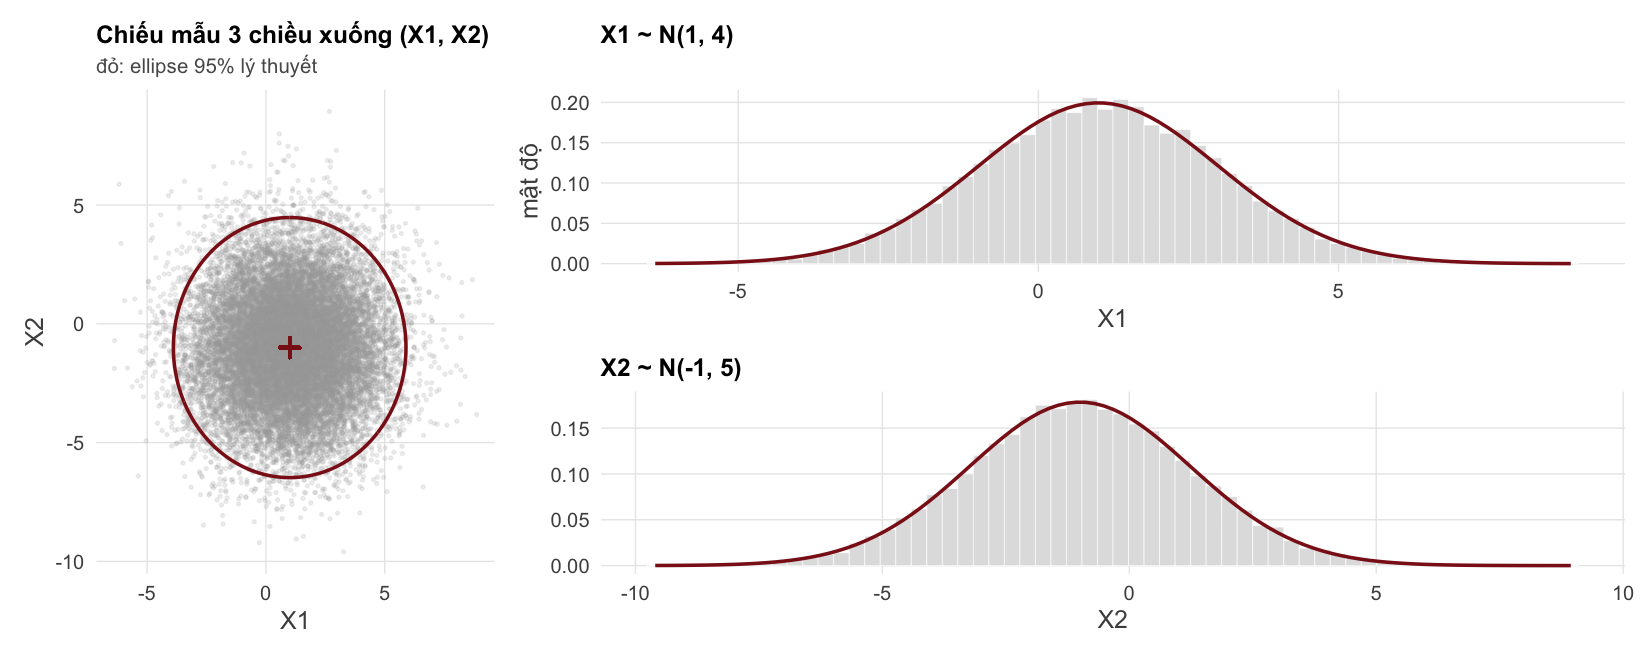

In [4]:
options(repr.plot.width = 11, repr.plot.height = 4.4)

ell12 <- conf_ellipse(c(1, -1), matrix(c(4, 0, 0, 5), 2))

p_scatter <- ggplot(dat, aes(X1, X2)) +
  geom_point(colour = SOFT, alpha = 0.16, size = 0.5) +
  geom_path(data = ell12, aes(x, y), colour = ACC, linewidth = 0.8) +
  geom_point(x = 1, y = -1, colour = ACC, size = 2.4, shape = 3, stroke = 1.1) +
  coord_fixed() +
  labs(title = "Chiếu mẫu 3 chiều xuống (X1, X2)",
       subtitle = "đỏ: ellipse 95% lý thuyết")

d1 <- ggplot(dat, aes(X1)) +
  geom_histogram(aes(y = after_stat(density)), bins = 60,
                 fill = "grey88", colour = "white", linewidth = 0.15) +
  stat_function(fun = dnorm, args = list(mean = 1, sd = 2), colour = ACC, linewidth = 0.8) +
  labs(title = "X1 ~ N(1, 4)", y = "mật độ")

d2 <- ggplot(dat, aes(X2)) +
  geom_histogram(aes(y = after_stat(density)), bins = 60,
                 fill = "grey88", colour = "white", linewidth = 0.15) +
  stat_function(fun = dnorm, args = list(mean = -1, sd = sqrt(5)), colour = ACC, linewidth = 0.8) +
  labs(title = "X2 ~ N(-1, 5)", y = NULL)

p_scatter | (d1 / d2)

### Kiểm tra điều dễ nhầm: $X_3$ có "rò rỉ" vào phân phối biên không?

Nếu phân phối biên thực sự không phụ thuộc $X_3$, thì khi ta chỉ giữ lại những quan sát có $X_3$ *rất nhỏ* hoặc *rất lớn*, đám mây $(X_1,X_2)$ phải **dịch chuyển** — vì $X_1$ tương quan với $X_3$. Nhưng khi gộp tất cả lại thì các dịch chuyển đó triệt tiêu và ta thu về đúng $\mathcal N_2$ ở trên.

              lat_X3 mean_X1 sd_X1 mean_X2 sd_X2
1 X3 thấp (33% dưới)  1.7781 1.886 -0.9622 2.246
2            X3 giữa  0.9892 1.868 -0.9946 2.228
3  X3 cao (33% trên)  0.2192 1.908 -0.9723 2.259


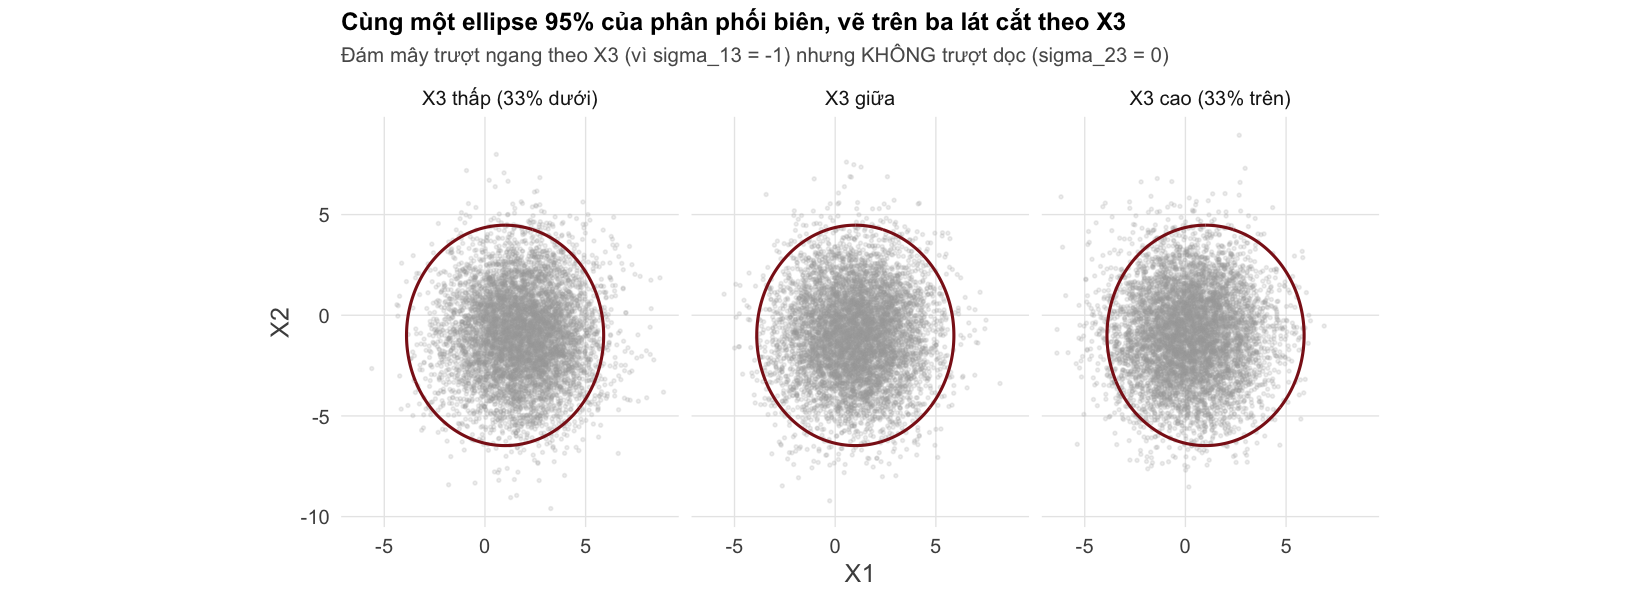

In [5]:
options(repr.plot.width = 11, repr.plot.height = 4.0)

dat <- dat %>%
  mutate(lat_X3 = cut(X3, breaks = quantile(X3, c(0, 1/3, 2/3, 1)),
                      labels = c("X3 thấp (33% dưới)", "X3 giữa", "X3 cao (33% trên)"),
                      include.lowest = TRUE))

slice_stats <- dat %>%
  group_by(lat_X3) %>%
  summarise(mean_X1 = mean(X1), sd_X1 = sd(X1),
            mean_X2 = mean(X2), sd_X2 = sd(X2), .groups = "drop")
print(as.data.frame(slice_stats))

ggplot(dat, aes(X1, X2)) +
  geom_point(colour = SOFT, alpha = 0.18, size = 0.5) +
  geom_path(data = ell12, aes(x, y), colour = ACC, linewidth = 0.7) +
  facet_wrap(~ lat_X3) +
  coord_fixed() +
  labs(title = "Cùng một ellipse 95% của phân phối biên, vẽ trên ba lát cắt theo X3",
       subtitle = "Đám mây trượt ngang theo X3 (vì sigma_13 = -1) nhưng KHÔNG trượt dọc (sigma_23 = 0)")

### Đọc ra từ output ở trên

- Kỳ vọng mẫu $(0.996,\,-0.976)$ và hiệp phương sai mẫu $\begin{pmatrix}3.97&0.044\\0.044&5.04\end{pmatrix}$ khớp $\big((1,-1)',\ \mathrm{diag}(4,5)\big)$; tương quan mẫu $0.0098$ — bằng 0 trong sai số Monte Carlo ($\approx 1/\sqrt{20000}=0.007$).
- Ellipse lý thuyết (vẽ **không** dùng dữ liệu) ôm khít đám mây, và hai histogram nằm đúng dưới hai mật độ $\mathcal N(1,4)$, $\mathcal N(-1,5)$.
- Ba lát cắt theo $X_3$: trung bình $X_1$ trượt $1.78 \to 0.99 \to 0.22$ (vì $\sigma_{13}=-1$), còn trung bình $X_2$ đứng yên ở $\approx -0.97$ (vì $\sigma_{23}=0$). **Gộp cả ba lát lại thì các dịch chuyển triệt tiêu** và ta thu về đúng phân phối biên — đó chính là nội dung của định lý.
- Chi tiết đáng để ý, dẫn thẳng sang Bài 2.3: trong *từng* lát cắt, $\mathrm{sd}(X_1)\approx 1.87$–$1.91$ chứ không phải $2$. Biết $X_3$ (dù chỉ biết thô theo ba nhóm) đã làm $X_1$ bớt biến động; còn $\mathrm{sd}(X_2)\approx 2.25\approx\sqrt5$ thì không đổi.

---
## Bài 2.2 — Không tương quan $\Rightarrow$ độc lập, nhưng **chỉ khi** chuẩn đồng thời

Kết quả lời giải, đọc thẳng từ $\boldsymbol\Sigma$:

| cặp | hiệp phương sai | kết luận |
|---|---|---|
| $X_1, X_2$ | $\sigma_{12}=0$ | độc lập |
| $X_1, X_3$ | $\sigma_{13}=-1$ | phụ thuộc |
| $(X_1,X_3), X_2$ | $(\sigma_{12},\sigma_{32})'=\mathbf 0$ | độc lập |
| $X_1,\; X_1+3X_2-2X_3$ | $\sigma_{11}+3\sigma_{12}-2\sigma_{13}=6$ | phụ thuộc |

Cách nhìn trực quan cho **độc lập**: cắt dữ liệu theo biến điều kiện; nếu độc lập thì phân phối của biến kia **không đổi hình dạng lẫn vị trí** qua các lát cắt.

In [6]:
cat("Ma trận hiệp phương sai mẫu:\n"); print(round(cov(dat[, 1:3]), 3))
cat("\nMa trận tương quan mẫu:\n");     print(round(cor(dat[, 1:3]), 3))

V <- dat$X1 + 3 * dat$X2 - 2 * dat$X3
cmp("Cov(X1, X1 + 3X2 - 2X3)", 6, cov(dat$X1, V))
cmp("Var(X1 + 3X2 - 2X3) = c'Sigma c", drop(t(c(1,3,-2)) %*% Sigma %*% c(1,3,-2)), var(V))

Ma trận hiệp phương sai mẫu:
       X1     X2     X3
X1  3.968  0.044 -1.005
X2  0.044  5.037 -0.008
X3 -1.005 -0.008  2.035

Ma trận tương quan mẫu:
       X1     X2     X3
X1  1.000  0.010 -0.354
X2  0.010  1.000 -0.003
X3 -0.354 -0.003  1.000

Cov(X1, X1 + 3X2 - 2X3)
  lý thuyết :        6 
  mô phỏng  :    6.111 

Var(X1 + 3X2 - 2X3) = c'Sigma c
  lý thuyết :       61 
  mô phỏng  :    61.82 


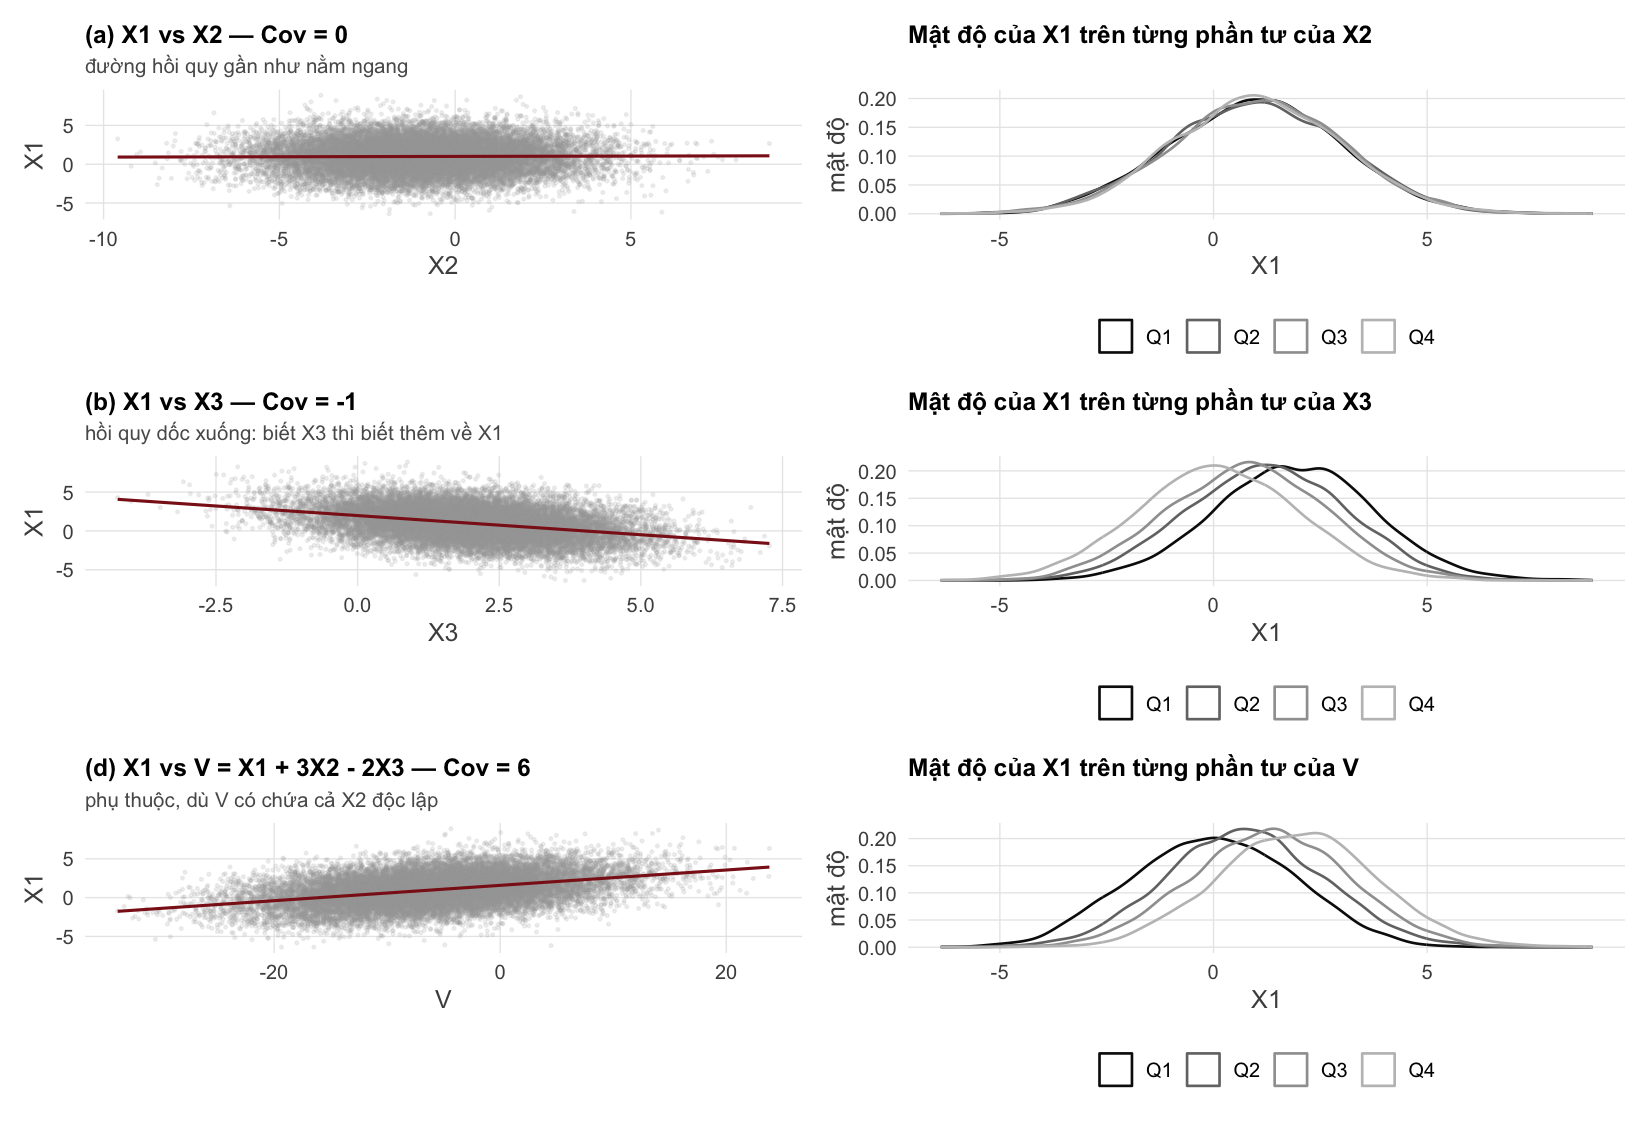

In [7]:
options(repr.plot.width = 11, repr.plot.height = 7.5)

band <- function(v) cut(v, breaks = quantile(v, c(0, .25, .5, .75, 1)),
                        labels = c("Q1", "Q2", "Q3", "Q4"), include.lowest = TRUE)

sl <- dat %>% mutate(bX2 = band(X2), bX3 = band(X3), V = V, bV = band(V))

sc <- function(d, xv, yv, ttl, sub) {
  ggplot(d, aes({{ xv }}, {{ yv }})) +
    geom_point(colour = SOFT, alpha = 0.15, size = 0.45) +
    geom_smooth(method = "lm", formula = y ~ x, se = FALSE, colour = ACC, linewidth = 0.7) +
    labs(title = ttl, subtitle = sub)
}

dens <- function(d, xv, grp, ttl) {
  ggplot(d, aes({{ xv }}, colour = {{ grp }})) +
    geom_density(linewidth = 0.6) +
    scale_colour_grey(start = 0.05, end = 0.75) +
    labs(title = ttl, y = "mật độ")
}

(sc(sl, X2, X1, "(a) X1 vs X2 — Cov = 0", "đường hồi quy gần như nằm ngang") |
 dens(sl, X1, bX2, "Mật độ của X1 trên từng phần tư của X2")) /
(sc(sl, X3, X1, "(b) X1 vs X3 — Cov = -1", "hồi quy dốc xuống: biết X3 thì biết thêm về X1") |
 dens(sl, X1, bX3, "Mật độ của X1 trên từng phần tư của X3")) /
(sc(sl, V,  X1, "(d) X1 vs V = X1 + 3X2 - 2X3 — Cov = 6", "phụ thuộc, dù V có chứa cả X2 độc lập") |
 dens(sl, X1, bV, "Mật độ của X1 trên từng phần tư của V"))

### Câu (c): $(X_1,X_3)$ độc lập với $X_2$ — độc lập giữa hai **khối**

Không chỉ từng biến, mà cả *cấu trúc phụ thuộc bên trong* khối $(X_1,X_3)$ cũng phải không đổi khi ta điều kiện theo $X_2$: cùng tâm, cùng hình ellipse.

Thống kê của khối (X1, X3) trên từng phần tư của X2 — lý thuyết: 1, 2, 4, 2, -1
  bX2 mean_X1 mean_X3 var_X1 var_X3  cov_13
1  Q1  0.9699   2.008  3.988  1.975 -0.9853
2  Q2  0.9746   1.968  4.067  2.043 -1.0321
3  Q3  1.0251   1.962  3.955  2.065 -1.0187
4  Q4  1.0123   1.995  3.863  2.057 -0.9857


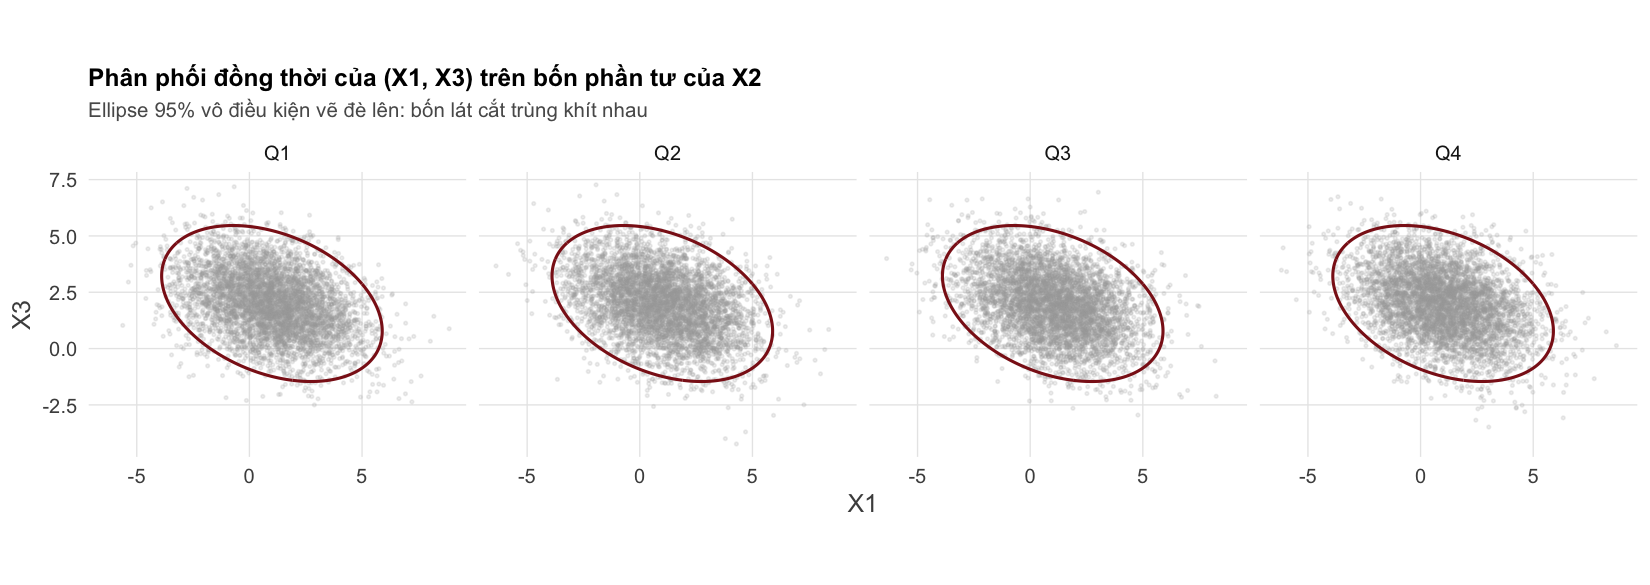

In [8]:
options(repr.plot.width = 11, repr.plot.height = 3.9)

blk <- sl %>% group_by(bX2) %>%
  summarise(mean_X1 = mean(X1), mean_X3 = mean(X3),
            var_X1 = var(X1), var_X3 = var(X3), cov_13 = cov(X1, X3), .groups = "drop")
cat("Thống kê của khối (X1, X3) trên từng phần tư của X2 — lý thuyết: 1, 2, 4, 2, -1\n")
print(as.data.frame(blk))

ell13 <- conf_ellipse(c(1, 2), Sigma[c(1, 3), c(1, 3)])

ggplot(sl, aes(X1, X3)) +
  geom_point(colour = SOFT, alpha = 0.18, size = 0.45) +
  geom_path(data = ell13, aes(x, y), colour = ACC, linewidth = 0.7) +
  facet_wrap(~ bX2, nrow = 1) +
  coord_fixed() +
  labs(title = "Phân phối đồng thời của (X1, X3) trên bốn phần tư của X2",
       subtitle = "Ellipse 95% vô điều kiện vẽ đè lên: bốn lát cắt trùng khít nhau")

### Vì sao phải nhấn mạnh "**chuẩn đồng thời**"?

Phản ví dụ kinh điển: lấy $Z\sim\mathcal N(0,1)$ và $S=\pm1$ với xác suất $1/2$, độc lập với $Z$; đặt $W=SZ$.
Khi đó $W\sim\mathcal N(0,1)$, $Z\sim\mathcal N(0,1)$, $\operatorname{Cov}(Z,W)=0$ — **nhưng** $|W|=|Z|$, tức là biết $Z$ thì biết luôn $|W|$: hai biến phụ thuộc chặt. Cặp $(Z,W)$ có hai biên chuẩn nhưng **không** chuẩn đồng thời, nên định lý không áp dụng được.

Cov(Z, W) = -0.0315  | Cor(Z, W) = -0.0314  | nhưng Cor(|Z|, |W|) = 1 
Kiểm định Shapiro cho tổ hợp Z + W (nếu chuẩn đồng thời thì Z + W phải chuẩn): p = <2e-16 


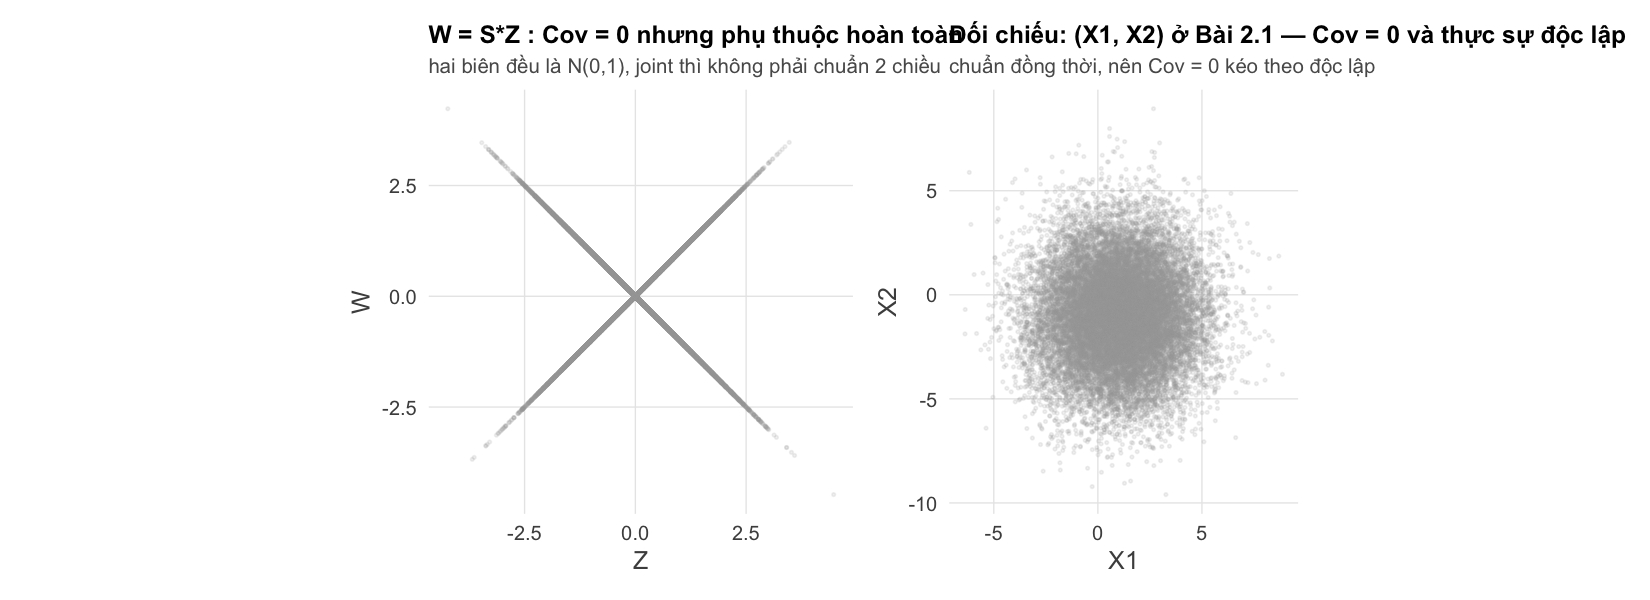

In [9]:
options(repr.plot.width = 11, repr.plot.height = 4.0)

Z  <- rnorm(N); S <- sample(c(-1, 1), N, replace = TRUE); W <- S * Z
ce <- data.frame(Z = Z, W = W)

cat("Cov(Z, W) =", round(cov(Z, W), 4),
    " | Cor(Z, W) =", round(cor(Z, W), 4),
    " | nhưng Cor(|Z|, |W|) =", round(cor(abs(Z), abs(W)), 4), "\n")
cat("Kiểm định Shapiro cho tổ hợp Z + W (nếu chuẩn đồng thời thì Z + W phải chuẩn): p =",
    format.pval(shapiro.test(head(Z + W, 5000))$p.value, digits = 3), "\n")

pA <- ggplot(ce, aes(Z, W)) + geom_point(colour = SOFT, alpha = 0.15, size = 0.45) +
  coord_fixed() + labs(title = "W = S*Z : Cov = 0 nhưng phụ thuộc hoàn toàn",
                       subtitle = "hai biên đều là N(0,1), joint thì không phải chuẩn 2 chiều")
pB <- ggplot(data.frame(x = dat$X1, y = dat$X2), aes(x, y)) +
  geom_point(colour = SOFT, alpha = 0.15, size = 0.45) + coord_fixed() +
  labs(title = "Đối chiếu: (X1, X2) ở Bài 2.1 — Cov = 0 và thực sự độc lập",
       subtitle = "chuẩn đồng thời, nên Cov = 0 kéo theo độc lập", x = "X1", y = "X2")
pA | pB

### Đọc ra từ output ở trên

- Hiệp phương sai mẫu tái tạo đúng $\boldsymbol\Sigma$: $\widehat\sigma_{13}=-1.005$, $\widehat\sigma_{12}=0.044$, $\widehat\sigma_{23}=-0.008$. $\operatorname{Cov}(X_1,V)=6.11$ (lý thuyết $6$) và $\operatorname{Var}(V)=61.8$ (lý thuyết $\mathbf c'\boldsymbol\Sigma\mathbf c=61$).
- **(a)** Đường hồi quy của $X_1$ theo $X_2$ nằm ngang và ba đường mật độ của $X_1$ trên bốn phần tư của $X_2$ chồng khít lên nhau — đúng nghĩa "biết $X_2$ không nói gì thêm về $X_1$".
- **(b)** Với $X_3$ thì ngược lại: đường hồi quy dốc xuống và các mật độ **trượt ngang** rõ rệt.
- **(d)** Dù $V=X_1+3X_2-2X_3$ có chứa $X_2$ (thành phần độc lập với $X_1$), $V$ vẫn phụ thuộc $X_1$ — vì nó cũng chứa chính $X_1$ và cả $X_3$. Độc lập **không** cộng dồn qua tổ hợp tuyến tính.
- **(c)** Bảng theo phần tư của $X_2$: $\overline{X_1}\approx 0.97$–$1.03$, $\overline{X_3}\approx 1.96$–$2.01$, $\widehat{\operatorname{Var}}$ $\approx 3.9$–$4.1$ và $2.0$–$2.1$, $\widehat{\operatorname{Cov}}(X_1,X_3)\approx -0.99$–$-1.03$. Không chỉ tâm mà **toàn bộ cấu trúc phụ thuộc** của khối $(X_1,X_3)$ đứng yên — đó mới là độc lập giữa hai khối.
- Phản ví dụ: $\operatorname{Cov}(Z,W)=-0.03$ (bằng 0 trong sai số MC) nhưng $\operatorname{Cor}(|Z|,|W|)=1.000$ — phụ thuộc tuyệt đối. Shapiro cho $Z+W$ có $p<2\times10^{-16}$: cặp này **không** chuẩn đồng thời, nên giả thiết của định lý sụp và kết luận "độc lập" không còn dùng được.

---
## Bài 2.3 — Phân phối có điều kiện: đường hồi quy và phương sai *co lại*

Kết quả:

$$X_1\mid X_3=x_3 \sim \mathcal N\!\Big(2-\tfrac12 x_3,\ \tfrac72\Big),\qquad
X_1\mid (X_2,X_3) \sim \mathcal N\!\Big(2-\tfrac12 x_3,\ \tfrac72\Big),\qquad
X_2\mid (X_1,X_3) \sim \mathcal N(-1,\,5).$$

Ba điều cần thấy bằng mắt:

1. $\mathbb E[X_1\mid X_3=x_3]$ là một **đường thẳng** theo $x_3$ — hồi quy tuyến tính không phải giả định, mà là *hệ quả* của tính chuẩn đồng thời.
2. Phương sai có điều kiện $7/2$ **không phụ thuộc** $x_3$ (đồng phương sai) và **nhỏ hơn** phương sai vô điều kiện $4$: điều kiện = thu được thông tin.
3. Thêm $X_2$ vào tập điều kiện **không giúp gì thêm**, đúng như tính độc lập ở Bài 2.2(c).

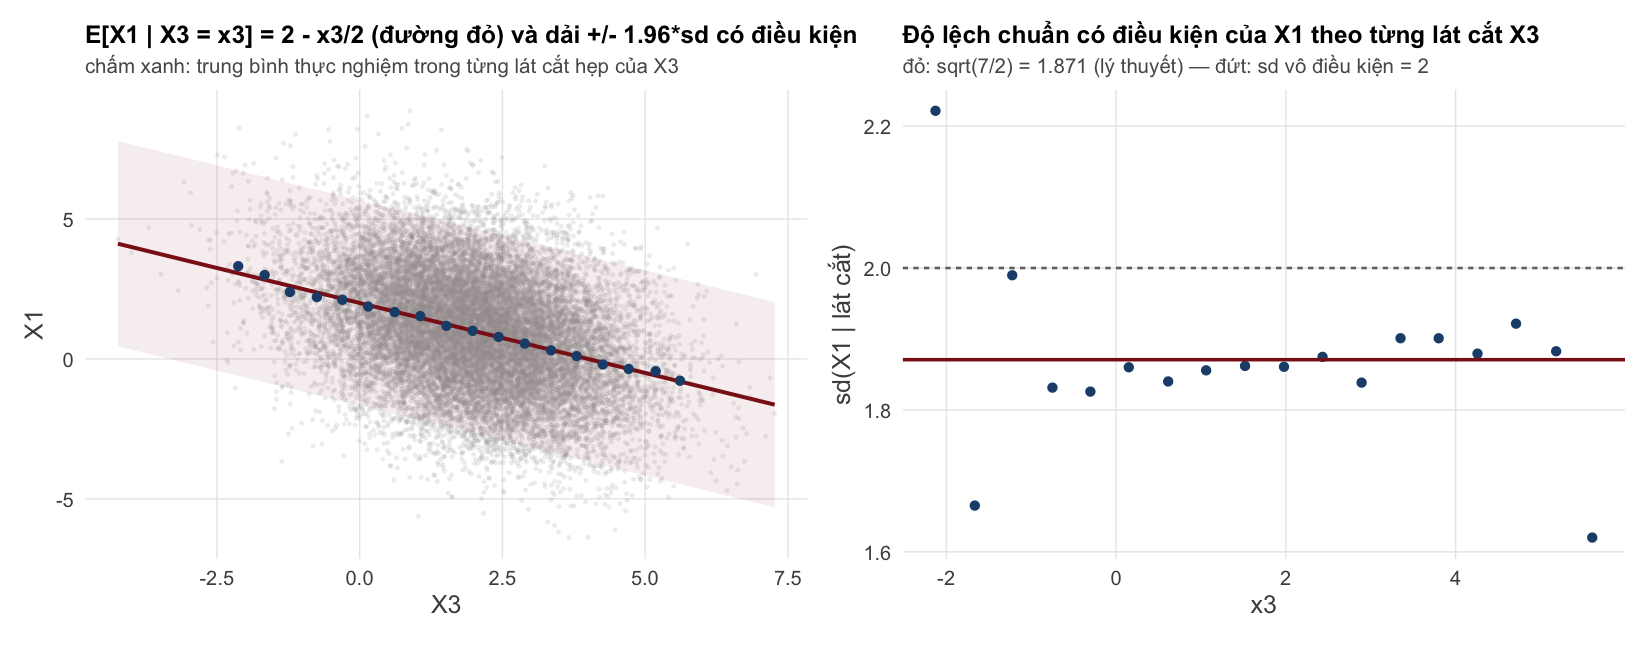

In [10]:
options(repr.plot.width = 11, repr.plot.height = 4.3)

grid_x3 <- seq(min(dat$X3), max(dat$X3), length.out = 200)
line_th <- data.frame(X3 = grid_x3,
                      m  = 2 - 0.5 * grid_x3,
                      lo = 2 - 0.5 * grid_x3 - 1.96 * sqrt(3.5),
                      hi = 2 - 0.5 * grid_x3 + 1.96 * sqrt(3.5))

bin_stats <- dat %>%
  mutate(b = cut(X3, breaks = seq(min(X3), max(X3), length.out = 26))) %>%
  group_by(b) %>%
  filter(n() >= 40) %>%
  summarise(x3 = mean(X3), m = mean(X1), s = sd(X1), n = n(), .groups = "drop")

pm <- ggplot(dat, aes(X3, X1)) +
  geom_point(colour = SOFT, alpha = 0.13, size = 0.45) +
  geom_ribbon(data = line_th, aes(x = X3, ymin = lo, ymax = hi), inherit.aes = FALSE,
              fill = ACC, alpha = 0.08) +
  geom_line(data = line_th, aes(X3, m), colour = ACC, linewidth = 0.9) +
  geom_point(data = bin_stats, aes(x3, m), colour = ACC2, size = 1.6) +
  labs(title = "E[X1 | X3 = x3] = 2 - x3/2 (đường đỏ) và dải +/- 1.96*sd có điều kiện",
       subtitle = "chấm xanh: trung bình thực nghiệm trong từng lát cắt hẹp của X3")

ps <- ggplot(bin_stats, aes(x3, s)) +
  geom_point(colour = ACC2, size = 1.6) +
  geom_hline(yintercept = sqrt(3.5), colour = ACC, linewidth = 0.8) +
  geom_hline(yintercept = 2, colour = "grey45", linetype = "22", linewidth = 0.6) +
  labs(title = "Độ lệch chuẩn có điều kiện của X1 theo từng lát cắt X3",
       subtitle = "đỏ: sqrt(7/2) = 1.871 (lý thuyết) — đứt: sd vô điều kiện = 2",
       y = "sd(X1 | lát cắt)")
pm | ps

                   lab mean_tn sd_tn mean_lt sd_lt
1  x3 = 0.5  (n = 958)  1.7662 1.843    1.75 1.871
2 x3 = 2.0  (n = 1708)  0.9594 1.864    1.00 1.871
3  x3 = 3.5  (n = 953)  0.1804 1.965    0.25 1.871


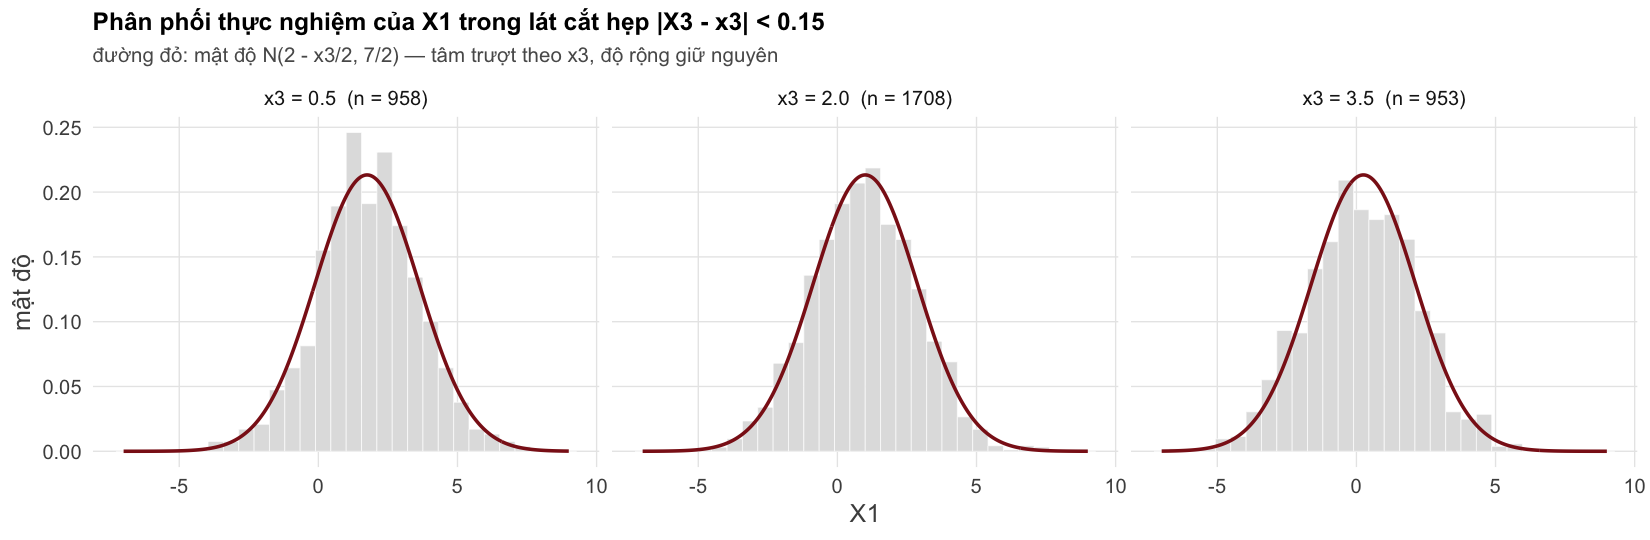

In [11]:
# Lát cắt hẹp quanh ba giá trị x3 cụ thể: so histogram với mật độ chuẩn lý thuyết
options(repr.plot.width = 11, repr.plot.height = 3.6)

targets <- c(0.5, 2, 3.5); h <- 0.15
slices <- lapply(targets, function(t0) {
  s <- dat %>% filter(abs(X3 - t0) < h) %>% transmute(X1, x3 = t0)
  s$lab <- sprintf("x3 = %.1f  (n = %d)", t0, nrow(s)); s
}) %>% bind_rows()

curves <- lapply(targets, function(t0) {
  g <- seq(-7, 9, length.out = 300)
  data.frame(X1 = g, d = dnorm(g, 2 - 0.5 * t0, sqrt(3.5)),
             lab = sprintf("x3 = %.1f  (n = %d)", t0, sum(abs(dat$X3 - t0) < h)))
}) %>% bind_rows()

print(slices %>% group_by(lab) %>%
        summarise(mean_tn = mean(X1), sd_tn = sd(X1),
                  mean_lt = 2 - 0.5 * first(x3), sd_lt = sqrt(3.5), .groups = "drop") %>%
        as.data.frame())

ggplot(slices, aes(X1)) +
  geom_histogram(aes(y = after_stat(density)), bins = 30,
                 fill = "grey88", colour = "white", linewidth = 0.15) +
  geom_line(data = curves, aes(X1, d), colour = ACC, linewidth = 0.8) +
  facet_wrap(~ lab, nrow = 1) +
  labs(title = "Phân phối thực nghiệm của X1 trong lát cắt hẹp |X3 - x3| < 0.15",
       subtitle = "đường đỏ: mật độ N(2 - x3/2, 7/2) — tâm trượt theo x3, độ rộng giữ nguyên",
       y = "mật độ")

In [12]:
# (b) và (c): thêm biến điều kiện có làm giảm phương sai không?
fit_1_3   <- lm(X1 ~ X3,      data = dat)
fit_1_23  <- lm(X1 ~ X2 + X3, data = dat)
fit_2_13  <- lm(X2 ~ X1 + X3, data = dat)

cat("(a) X1 ~ X3    : hệ số =", round(coef(fit_1_3), 4),
    "| phương sai phần dư =", round(summary(fit_1_3)$sigma^2, 4), "  [lý thuyết: 2, -0.5, 3.5]\n")
cat("(b) X1 ~ X2+X3 : hệ số =", round(coef(fit_1_23), 4),
    "| phương sai phần dư =", round(summary(fit_1_23)$sigma^2, 4), "  [lý thuyết: 2, 0, -0.5, 3.5]\n")
cat("(c) X2 ~ X1+X3 : hệ số =", round(coef(fit_2_13), 4),
    "| phương sai phần dư =", round(summary(fit_2_13)$sigma^2, 4), "  [lý thuyết: -1, 0, 0, 5]\n")

var_tab <- data.frame(
  dieu_kien = c("không", "biết X3", "biết X2, X3"),
  var_X1    = c(var(dat$X1), summary(fit_1_3)$sigma^2, summary(fit_1_23)$sigma^2),
  ly_thuyet = c(4, 3.5, 3.5))
print(var_tab)

(a) X1 ~ X3    : hệ số = 1.976 -0.4941 | phương sai phần dư = 3.471   [lý thuyết: 2, -0.5, 3.5]
(b) X1 ~ X2+X3 : hệ số = 1.983 0.0079 -0.4941 | phương sai phần dư = 3.471   [lý thuyết: 2, 0, -0.5, 3.5]
(c) X2 ~ X1+X3 : hệ số = -0.9908 0.0115 0.0015 | phương sai phần dư = 5.037   [lý thuyết: -1, 0, 0, 5]
    dieu_kien var_X1 ly_thuyet
1       không  3.968       4.0
2     biết X3  3.471       3.5
3 biết X2, X3  3.471       3.5


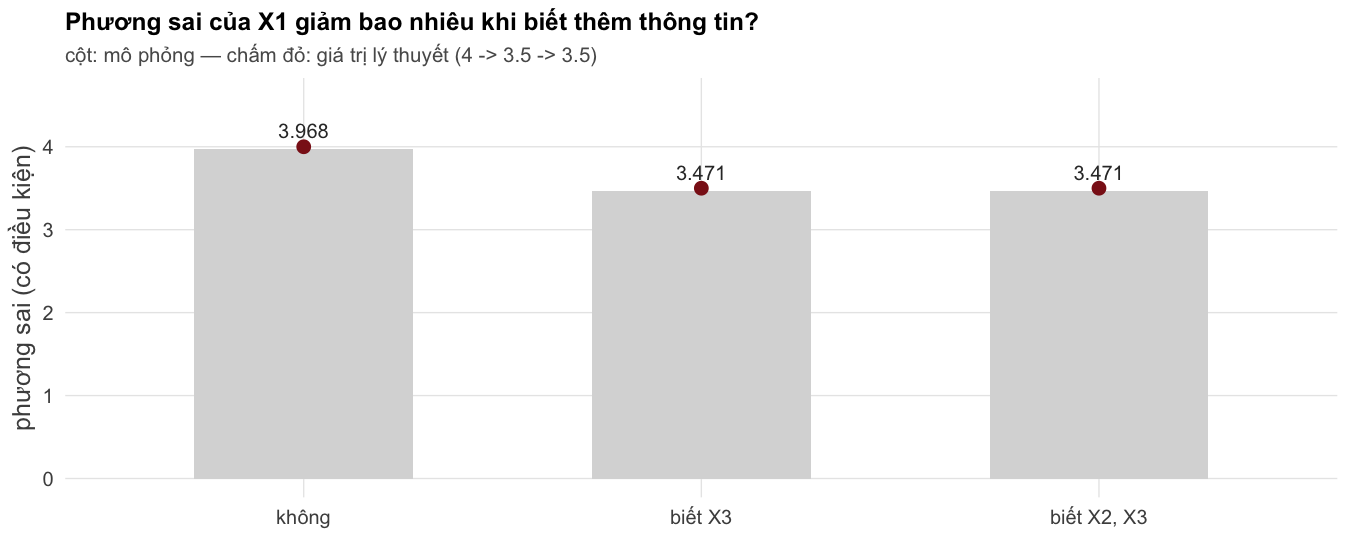

In [13]:
options(repr.plot.width = 9, repr.plot.height = 3.6)

ggplot(var_tab, aes(x = factor(dieu_kien, levels = dieu_kien))) +
  geom_col(aes(y = var_X1), fill = "grey85", width = 0.55) +
  geom_point(aes(y = ly_thuyet), colour = ACC, size = 2.6) +
  geom_text(aes(y = var_X1, label = round(var_X1, 3)), vjust = -0.8, size = 3.4, colour = INK) +
  ylim(0, 4.6) +
  labs(title = "Phương sai của X1 giảm bao nhiêu khi biết thêm thông tin?",
       subtitle = "cột: mô phỏng — chấm đỏ: giá trị lý thuyết (4 -> 3.5 -> 3.5)",
       x = NULL, y = "phương sai (có điều kiện)")

### Đọc ra từ output ở trên

- Trung bình trong ba lát cắt hẹp: $1.766$ / $0.959$ / $0.180$, so với công thức $2-x_3/2$ cho $1.75$ / $1.00$ / $0.25$; độ lệch chuẩn $1.84$ / $1.86$ / $1.97$ so với $\sqrt{7/2}=1.871$. Tâm **trượt** theo $x_3$, bề rộng **không** đổi.
- Hồi quy tuyến tính tái tạo đúng công thức có điều kiện: `X1 ~ X3` cho hệ số $(1.976,\,-0.494)$ và phương sai phần dư $3.471$ — chính là $\big(2,\,-\tfrac12,\,\tfrac72\big)$. Đây không phải trùng hợp: với dữ liệu chuẩn đồng thời, *hồi quy tuyến tính chính là kỳ vọng có điều kiện*, không phải một xấp xỉ.
- Thêm $X_2$ vào: hệ số của nó là $0.0079\approx 0$ và phương sai phần dư **y hệt** $3.471$. Bổ sung một biến độc lập không cải thiện được gì — đúng như Bài 2.2(c).
- Chiều ngược lại: `X2 ~ X1 + X3` cho hai hệ số $\approx 0$ và phương sai phần dư $5.037\approx\sigma_{22}=5$, tức $X_2\mid(X_1,X_3)$ trùng với phân phối biên của $X_2$.
- Mức giảm phương sai chỉ $4\to 3.5$ (12.5%) vì $\operatorname{Cor}(X_1,X_3)=-0.354$ và $0.354^2=0.125$. Điều kiện *luôn* làm phương sai giảm, nhưng giảm bao nhiêu thì do độ mạnh tương quan quyết định.

---
## Bài 2.4 — Tổ hợp tuyến tính, và "trực giao với cái gì?"

$$\boldsymbol\mu=\begin{pmatrix}2\\-3\\1\end{pmatrix},\qquad
\boldsymbol\Sigma=\begin{pmatrix}1&1&1\\1&3&2\\1&2&2\end{pmatrix}.$$

**(a)** $Y=3X_1-2X_2+X_3=\mathbf c'\mathbf X\sim\mathcal N(\mathbf c'\boldsymbol\mu,\ \mathbf c'\boldsymbol\Sigma\mathbf c)=\mathcal N(13,9)$.

**(b)** Tìm $\mathbf a$ để $X_2 \perp X_2-\mathbf a'\mathbf Z$ với $\mathbf Z=(X_1,X_3)'$:
$$\operatorname{Cov}\big(X_2,\ X_2-\mathbf a'\mathbf Z\big)=\sigma_{22}-a_1\sigma_{21}-a_2\sigma_{23}=3-a_1-2a_2=0
\iff a_1+2a_2=3 .$$

Nghiệm là **cả một đường thẳng** trong $\mathbb R^2$, không phải một điểm — và nó **khác** vectơ hệ số hồi quy $\boldsymbol\beta=\boldsymbol\Sigma_{2\mathbf Z}\boldsymbol\Sigma_{\mathbf{ZZ}}^{-1}=(0,1)'$. Phần dư hồi quy trực giao với $\mathbf Z$; đề bài lại yêu cầu trực giao với chính $X_2$. Hai yêu cầu khác nhau nên cho hai đáp án khác nhau.

In [14]:
mu2 <- c(2, -3, 1)
Sig2 <- matrix(c(1, 1, 1,
                 1, 3, 2,
                 1, 2, 2), nrow = 3, byrow = TRUE)

X2s <- mvrnorm(N, mu2, Sig2); colnames(X2s) <- c("X1", "X2", "X3")
d24 <- as.data.frame(X2s)

cvec <- c(3, -2, 1)
Y <- as.vector(X2s %*% cvec)
cmp("Y = 3X1 - 2X2 + X3 : kỳ vọng và phương sai", c(13, 9), c(mean(Y), var(Y)))


Y = 3X1 - 2X2 + X3 : kỳ vọng và phương sai
  lý thuyết :       13        9 
  mô phỏng  :   12.998    9.014 


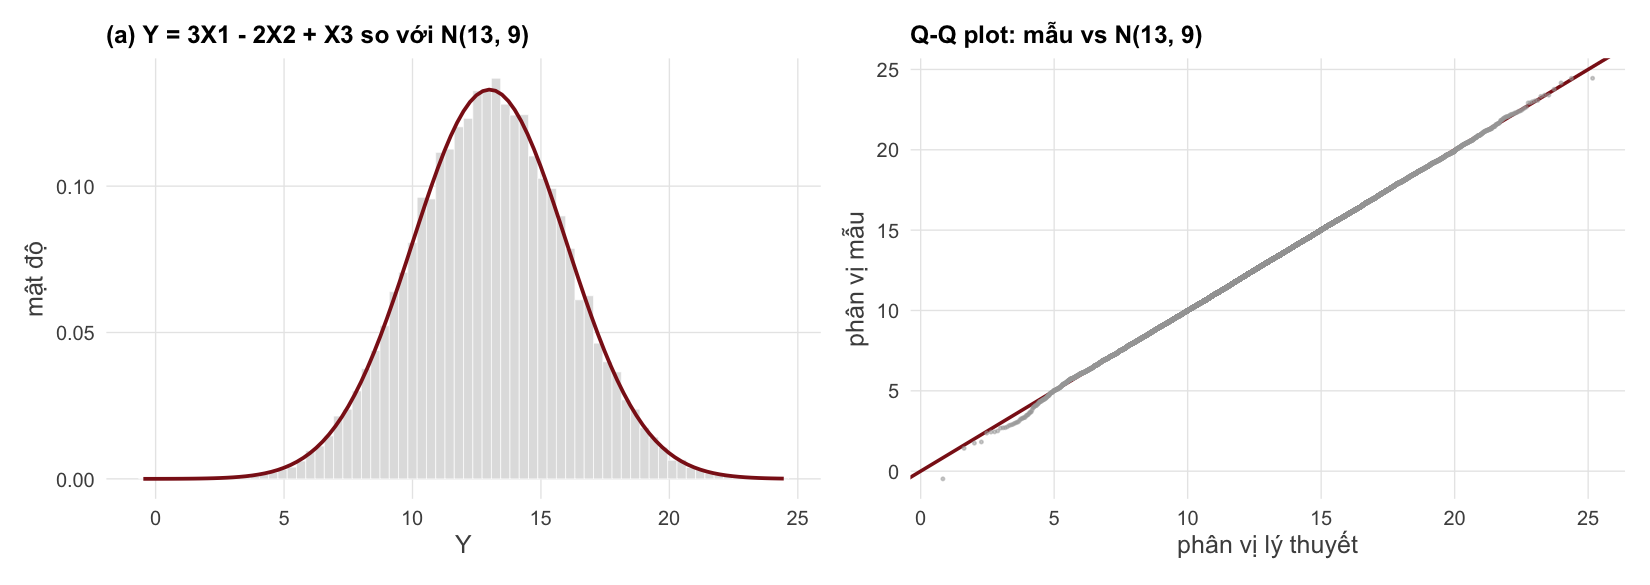

In [15]:
options(repr.plot.width = 11, repr.plot.height = 3.9)

pY <- ggplot(data.frame(Y = Y), aes(Y)) +
  geom_histogram(aes(y = after_stat(density)), bins = 70,
                 fill = "grey88", colour = "white", linewidth = 0.15) +
  stat_function(fun = dnorm, args = list(mean = 13, sd = 3), colour = ACC, linewidth = 0.85) +
  labs(title = "(a) Y = 3X1 - 2X2 + X3 so với N(13, 9)", y = "mật độ")

qq <- data.frame(theo = qnorm(ppoints(N), 13, 3), samp = sort(Y))
pQ <- ggplot(qq, aes(theo, samp)) +
  geom_abline(slope = 1, intercept = 0, colour = ACC, linewidth = 0.8) +
  geom_point(colour = SOFT, size = 0.4, alpha = 0.5) +
  labs(title = "Q-Q plot: mẫu vs N(13, 9)", x = "phân vị lý thuyết", y = "phân vị mẫu")
pY | pQ

Hệ số hồi quy beta của X2 lên (X1, X3): 0 1   -> a1 + 2a2 = 2 (khác 3)


Warning message:
“The following aesthetics were dropped during statistical transformation: fill.
ℹ This can happen when ggplot fails to infer the correct grouping structure in
  the data.
ℹ Did you forget to specify a `group` aesthetic or to convert a numerical
  variable into a factor?”


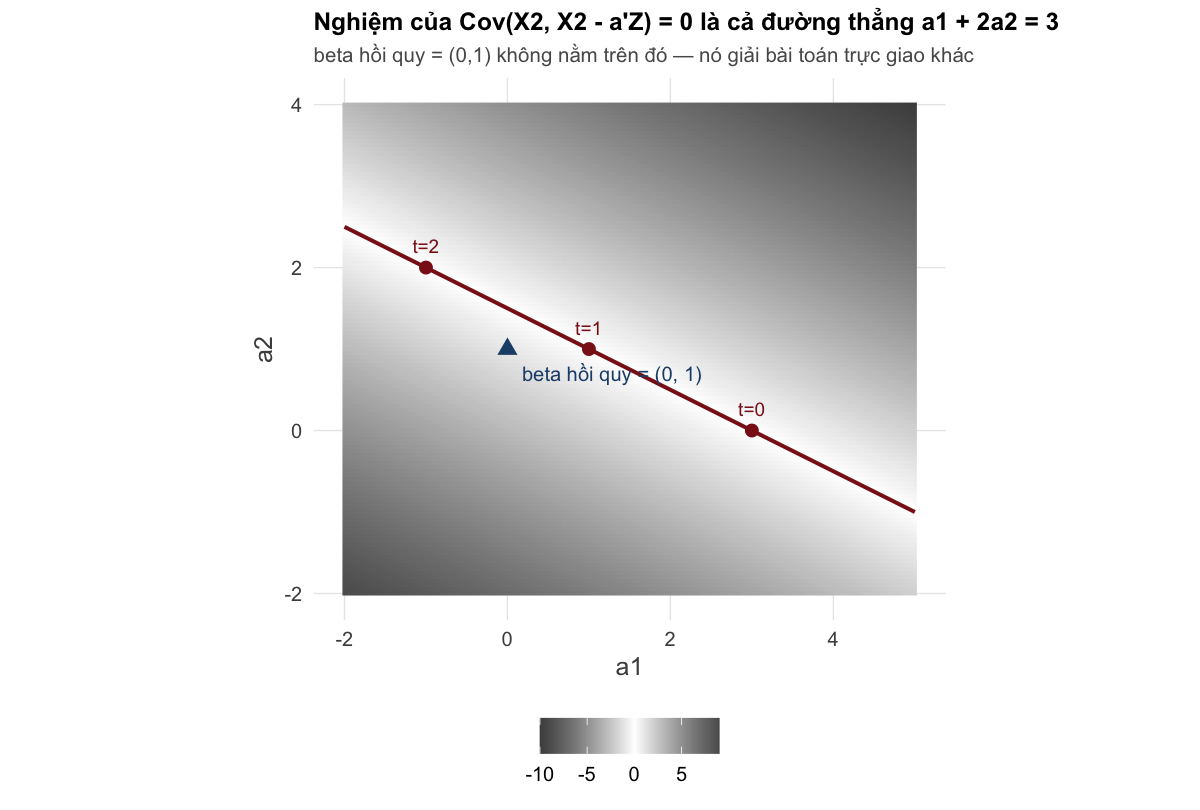

In [16]:
options(repr.plot.width = 8, repr.plot.height = 5.4)

# Bản đồ Cov(X2, W) trên lưới (a1, a2); đường mức 0 chính là a1 + 2a2 = 3
g <- expand.grid(a1 = seq(-2, 5, by = 0.05), a2 = seq(-2, 4, by = 0.05)) %>%
  mutate(cov_val = 3 - a1 - 2 * a2)

sols  <- data.frame(a1 = c(3, 1, -1), a2 = c(0, 1, 2), lab = c("t=0", "t=1", "t=2"))
beta  <- solve(Sig2[c(1, 3), c(1, 3)], Sig2[c(1, 3), 2])   # hệ số hồi quy X2 ~ (X1, X3)
cat("Hệ số hồi quy beta của X2 lên (X1, X3):", round(beta, 4),
    "  -> a1 + 2a2 =", round(beta[1] + 2 * beta[2], 4), "(khác 3)\n")

ggplot(g, aes(a1, a2, fill = cov_val)) +
  geom_raster() +
  scale_fill_gradient2(low = "grey30", mid = "white", high = "grey30", midpoint = 0,
                       name = "Cov(X2, W)") +
  geom_contour(aes(z = cov_val), breaks = 0, colour = ACC, linewidth = 0.9) +
  geom_point(data = sols, aes(a1, a2), inherit.aes = FALSE, colour = ACC, size = 2.4) +
  geom_text(data = sols, aes(a1, a2, label = lab), inherit.aes = FALSE,
            vjust = -1.1, size = 3.2, colour = ACC) +
  annotate("point", x = beta[1], y = beta[2], colour = ACC2, size = 3, shape = 17) +
  annotate("text", x = beta[1] + 0.18, y = beta[2] - 0.3, label = "beta hồi quy = (0, 1)",
           hjust = 0, colour = ACC2, size = 3.4) +
  coord_fixed() +
  labs(title = "Nghiệm của Cov(X2, X2 - a'Z) = 0 là cả đường thẳng a1 + 2a2 = 3",
       subtitle = "beta hồi quy = (0,1) không nằm trên đó — nó giải bài toán trực giao khác")

In [17]:
Z <- X2s[, c(1, 3)]
mk <- function(a) as.vector(X2s[, 2] - Z %*% a)

tab <- lapply(list(`a = (3,0)` = c(3, 0), `a = (1,1)` = c(1, 1),
                   `a = (-1,2)` = c(-1, 2), `beta = (0,1)` = beta),
              function(a) {
                W <- mk(a)
                data.frame(cov_X2_W = cov(X2s[, 2], W),
                           cov_W_X1 = cov(W, Z[, 1]),
                           cov_W_X3 = cov(W, Z[, 2]))
              }) %>% bind_rows(.id = "vecto_a")
print(tab, digits = 3)
cat("\n-> Ba dòng đầu (a trên đường a1+2a2=3): cov với X2 bằng 0, nhưng cov với X1, X3 thì không.\n")
cat("-> Dòng cuối (beta hồi quy): ngược lại hoàn toàn — phần dư trực giao với Z, không trực giao với X2.\n")

       vecto_a  cov_X2_W cov_W_X1 cov_W_X3
1    a = (3,0) -0.021778 -2.01431  -1.0172
2    a = (1,1) -0.000885 -1.00353  -0.9941
3   a = (-1,2)  0.020008  0.00725  -0.9710
4 beta = (0,1)  1.021168  0.00859   0.0194

-> Ba dòng đầu (a trên đường a1+2a2=3): cov với X2 bằng 0, nhưng cov với X1, X3 thì không.
-> Dòng cuối (beta hồi quy): ngược lại hoàn toàn — phần dư trực giao với Z, không trực giao với X2.


### Đọc ra từ output ở trên

- **(a)** $\bar Y=12.998$, $\widehat{\operatorname{Var}}(Y)=9.014$ — khớp $\mathcal N(13,9)$; Q-Q plot thẳng trên toàn dải, kể cả hai đuôi.
- **(b)** Bảng kiểm chứng tách bạch hai bài toán trực giao khác nhau:

  | $\mathbf a$ | $\operatorname{Cov}(X_2,W)$ | $\operatorname{Cov}(W,X_1)$ | $\operatorname{Cov}(W,X_3)$ |
  |---|---|---|---|
  | $(3,0)$ | $-0.02$ | $-2.01$ | $-1.02$ |
  | $(1,1)$ | $-0.001$ | $-1.00$ | $-0.99$ |
  | $(-1,2)$ | $0.02$ | $0.007$ | $-0.97$ |
  | $\boldsymbol\beta=(0,1)$ | $\mathbf{1.02}$ | $0.009$ | $0.019$ |

  Ba $\mathbf a$ đầu nằm trên $a_1+2a_2=3$: phần dư trực giao với **$X_2$** nhưng vẫn tương quan với $X_1,X_3$. Còn $\boldsymbol\beta$ thì đúng ngược lại — phần dư trực giao với **cả khối $\mathbf Z$** (hai cột cuối $\approx 0$), nhưng $\operatorname{Cov}(X_2,W)=1.02$, đúng bằng giá trị lý thuyết $3-(0\cdot 1+1\cdot 2)=1$.
- Ghi chú thú vị: $\mathbf a=(-1,2)$ tình cờ cũng cho $\operatorname{Cov}(W,X_1)=\sigma_{21}-a_1\sigma_{11}-a_2\sigma_{31}=1+1-2=0$, nhưng vẫn còn tương quan với $X_3$ ($-1$). Trực giao với một biến không kéo theo trực giao với cả không gian sinh bởi $\mathbf Z$.
- Bản đồ nhiệt cho thấy rõ nghiệm là **một đường thẳng, không phải một điểm**: bài toán thiếu ràng buộc, một phương trình cho hai ẩn.

---
## Bài 2.9 — Lý thuyết mẫu: $\chi^2$, Hotelling $T^2$, và cái giá của việc ước lượng $\boldsymbol\Sigma$

Với $\mathbf X_1,\dots,\mathbf X_{60}\stackrel{iid}{\sim}\mathcal N_4(\boldsymbol\mu,\boldsymbol\Sigma)$:

| đại lượng | phân phối |
|---|---|
| (a) $\bar{\mathbf X}$ | $\mathcal N_4(\boldsymbol\mu,\ \Sigma/60)$ |
| (b) $(\mathbf X_1-\boldsymbol\mu)'\Sigma^{-1}(\mathbf X_1-\boldsymbol\mu)$ | $\chi^2(4)$ |
| (c) $n(\bar{\mathbf X}-\boldsymbol\mu)'\Sigma^{-1}(\bar{\mathbf X}-\boldsymbol\mu)$ | $\chi^2(4)$ |
| (d) $T^2=n(\bar{\mathbf X}-\boldsymbol\mu)'\mathbf S^{-1}(\bar{\mathbf X}-\boldsymbol\mu)$ | chính xác: $\tfrac{59}{14}\mathcal F(4,56)$; tiệm cận: $\chi^2(4)$ |

Điểm mấu chốt của câu (d): thay $\boldsymbol\Sigma$ (đã biết) bằng $\mathbf S$ (ước lượng) làm **đuôi phân phối dày lên**. Nếu vẫn dùng ngưỡng $\chi^2$ thì ta bác bỏ $H_0$ nhiều hơn mức $\alpha$ đã hứa. Mô phỏng dưới đây đo đúng lượng "nhiều hơn" đó.

In [18]:
p <- 4; n <- 60; Rrep <- 6000
Sig9 <- ar1(p, 0.5); mu9 <- rep(0, p); Sinv9 <- solve(Sig9)

mc <- function(n, R, mu, Sig) {
  Sinv <- solve(Sig); p <- length(mu)
  d1 <- d2 <- t2 <- numeric(R)
  for (r in seq_len(R)) {
    Zr    <- rmvnorm(n, mu, Sig)
    xbar  <- colMeans(Zr); dv <- xbar - mu
    d1[r] <- drop(t(Zr[1, ] - mu) %*% Sinv %*% (Zr[1, ] - mu))
    d2[r] <- n * drop(t(dv) %*% Sinv %*% dv)
    t2[r] <- n * drop(t(dv) %*% solve(cov(Zr)) %*% dv)
  }
  data.frame(d1 = d1, d2 = d2, T2 = t2)
}

system.time(sim <- mc(n, Rrep, mu9, Sig9))

cmp("Trung bình của (b), (c), (d) — E[chi2(4)] = 4",
    c(4, 4, 4), colMeans(sim))
cat("\nE[T2] chính xác = p(n-1)/(n-p-2) =", round(p * (n - 1) / (n - p - 2), 4), "\n")

   user  system elapsed 
  0.442   0.004   0.447 


Trung bình của (b), (c), (d) — E[chi2(4)] = 4
  lý thuyết :        4        4        4 
  mô phỏng  :    4.001    4.006    4.384 

E[T2] chính xác = p(n-1)/(n-p-2) = 4.37 


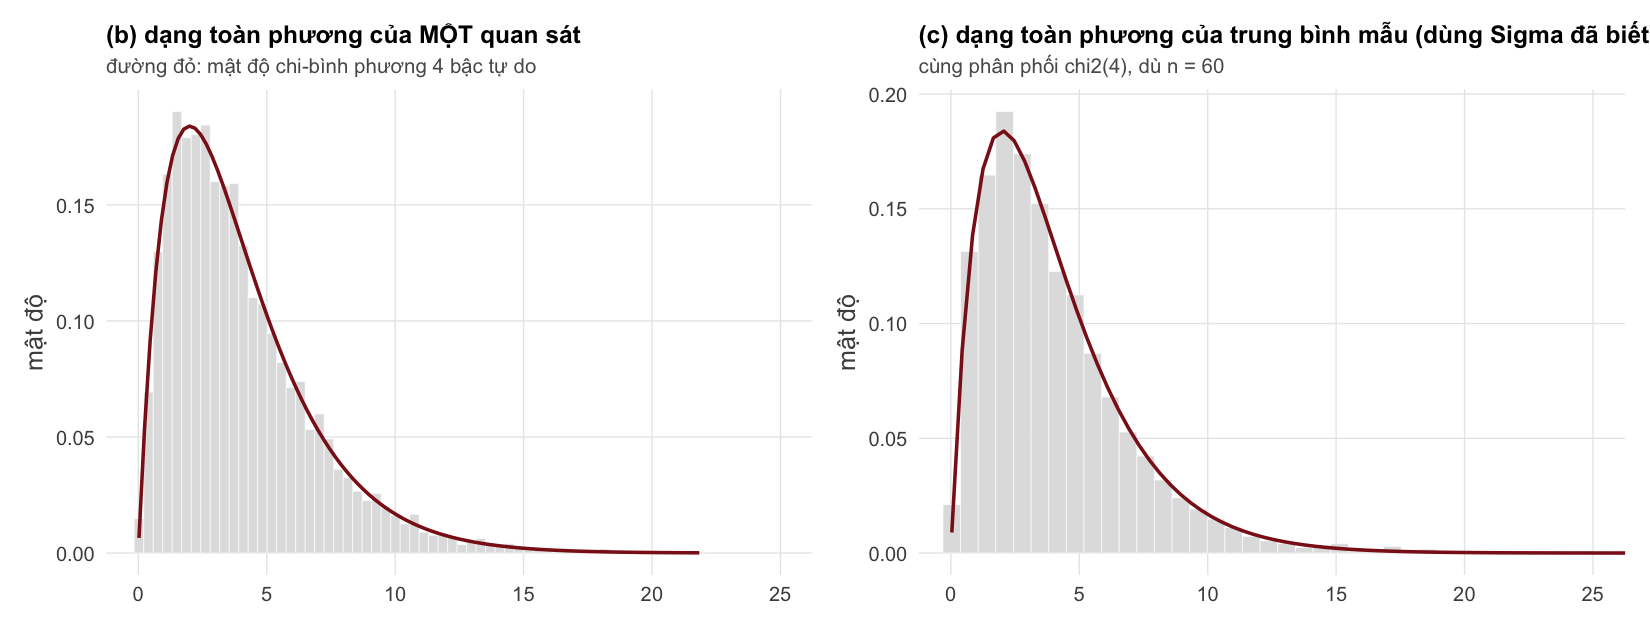

In [19]:
options(repr.plot.width = 11, repr.plot.height = 4.2)

hist_chi <- function(v, ttl, sub) {
  ggplot(data.frame(v = v), aes(v)) +
    geom_histogram(aes(y = after_stat(density)), bins = 60,
                   fill = "grey88", colour = "white", linewidth = 0.15) +
    stat_function(fun = dchisq, args = list(df = 4), colour = ACC, linewidth = 0.8) +
    coord_cartesian(xlim = c(0, 25)) +
    labs(title = ttl, subtitle = sub, y = "mật độ", x = NULL)
}

hist_chi(sim$d1, "(b) dạng toàn phương của MỘT quan sát",
         "đường đỏ: mật độ chi-bình phương 4 bậc tự do") |
hist_chi(sim$d2, "(c) dạng toàn phương của trung bình mẫu (dùng Sigma đã biết)",
         "cùng phân phối chi2(4), dù n = 60")

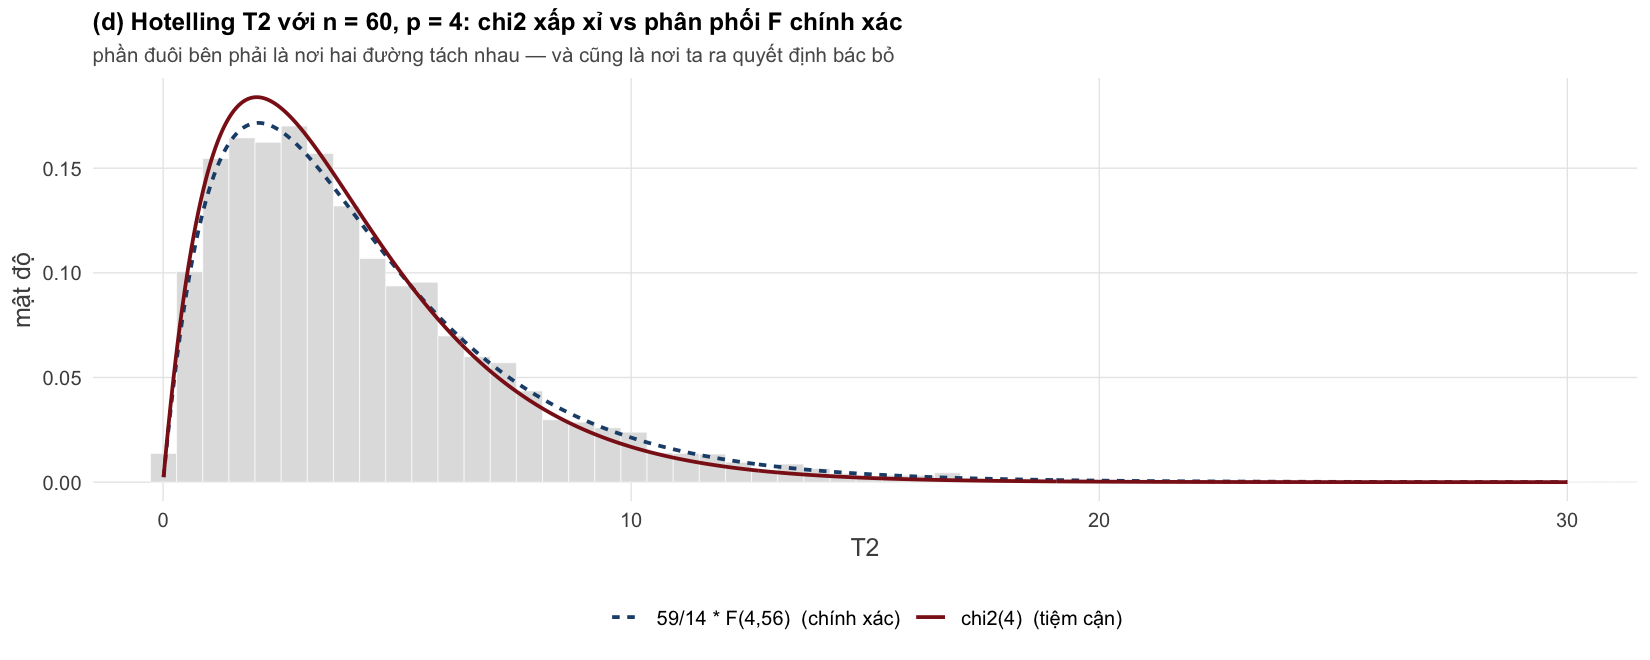

In [20]:
options(repr.plot.width = 11, repr.plot.height = 4.4)

cst  <- (n - 1) * p / (n - p)     # T2 = cst * F(p, n-p)
gx   <- seq(0.01, 30, length.out = 600)
dens_cmp <- bind_rows(
  data.frame(x = gx, d = dchisq(gx, 4),                      mod = "chi2(4)  (tiệm cận)"),
  data.frame(x = gx, d = df(gx / cst, p, n - p) / cst,       mod = "59/14 * F(4,56)  (chính xác)"))

ggplot(data.frame(T2 = sim$T2), aes(T2)) +
  geom_histogram(aes(y = after_stat(density)), bins = 70,
                 fill = "grey88", colour = "white", linewidth = 0.15) +
  geom_line(data = dens_cmp, aes(x, d, colour = mod, linetype = mod), linewidth = 0.85) +
  scale_colour_manual(values = c(ACC2, ACC)) +
  scale_linetype_manual(values = c("22", "solid")) +
  coord_cartesian(xlim = c(0, 30)) +
  labs(title = "(d) Hotelling T2 với n = 60, p = 4: chi2 xấp xỉ vs phân phối F chính xác",
       subtitle = "phần đuôi bên phải là nơi hai đường tách nhau — và cũng là nơi ta ra quyết định bác bỏ",
       y = "mật độ")

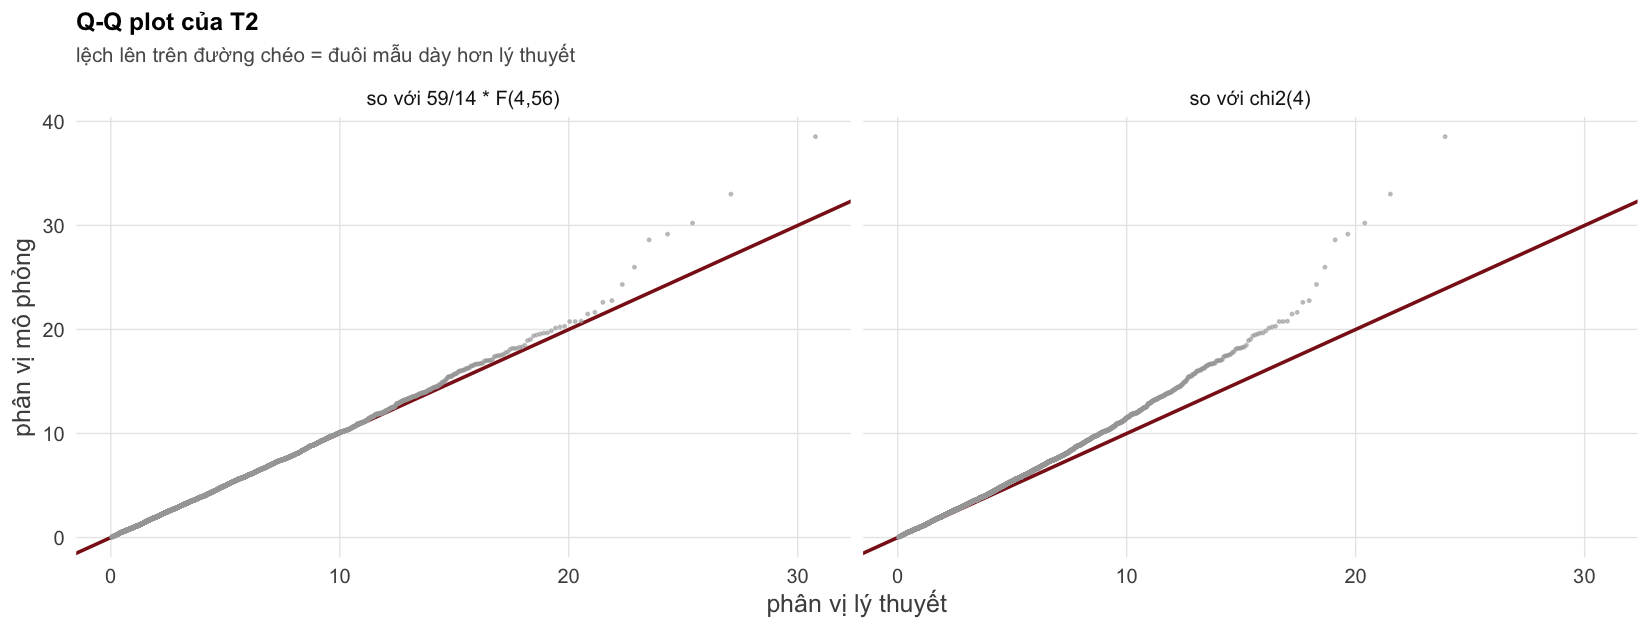

In [21]:
options(repr.plot.width = 11, repr.plot.height = 4.2)

qs   <- ppoints(length(sim$T2))
qqdf <- bind_rows(
  data.frame(theo = qchisq(qs, 4),          samp = sort(sim$T2), mod = "so với chi2(4)"),
  data.frame(theo = cst * qf(qs, p, n - p), samp = sort(sim$T2), mod = "so với 59/14 * F(4,56)"))

ggplot(qqdf, aes(theo, samp)) +
  geom_abline(slope = 1, intercept = 0, colour = ACC, linewidth = 0.8) +
  geom_point(colour = SOFT, size = 0.4, alpha = 0.55) +
  facet_wrap(~ mod) +
  labs(title = "Q-Q plot của T2", x = "phân vị lý thuyết", y = "phân vị mô phỏng",
       subtitle = "lệch lên trên đường chéo = đuôi mẫu dày hơn lý thuyết")

In [22]:
alpha <- 0.05
cut_chi <- qchisq(1 - alpha, p)
cut_F   <- cst * qf(1 - alpha, p, n - p)

err <- data.frame(
  nguong    = c("chi2(4) 95%", "59/14 * F(4,56) 95%"),
  gia_tri   = c(cut_chi, cut_F),
  sai_lam_I = c(mean(sim$T2 > cut_chi), mean(sim$T2 > cut_F)))
err$sai_so_tuong_doi <- err$sai_lam_I / alpha
print(err, digits = 4)
cat("\nMức ý nghĩa danh nghĩa là", alpha, "- cột sai_lam_I là tỉ lệ bác bỏ H0 thực tế khi H0 ĐÚNG.\n")

               nguong gia_tri sai_lam_I sai_so_tuong_doi
1         chi2(4) 95%   9.488   0.07700            1.540
2 59/14 * F(4,56) 95%  10.690   0.05067            1.013

Mức ý nghĩa danh nghĩa là 0.05 - cột sai_lam_I là tỉ lệ bác bỏ H0 thực tế khi H0 ĐÚNG.


### Xấp xỉ $\chi^2$ hỏng đến mức nào khi $n$ nhỏ?

Giữ nguyên $p=4$, cho $n$ chạy và đo tỉ lệ sai lầm loại I thực tế của **cùng một ngưỡng** $\chi^2_{4,0.95}$.

    n   chi2 F_dung
1   8 0.3780 0.0448
2  10 0.2824 0.0448
3  15 0.1948 0.0528
4  20 0.1568 0.0576
5  30 0.1092 0.0544
6  60 0.0780 0.0512
7 120 0.0532 0.0440
8 300 0.0524 0.0500


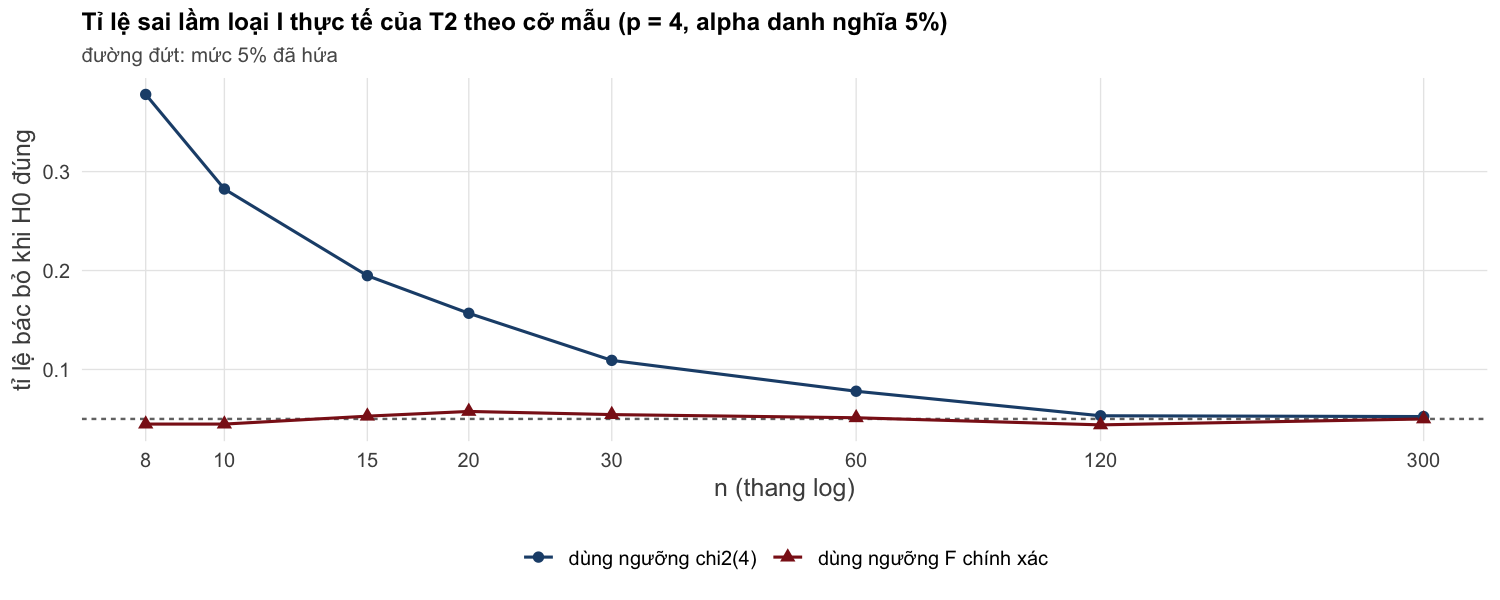

In [23]:
options(repr.plot.width = 10, repr.plot.height = 4.0)

ns  <- c(8, 10, 15, 20, 30, 60, 120, 300)
set.seed(11)
res <- lapply(ns, function(nn) {
  s <- mc(nn, 2500, mu9, Sig9)
  data.frame(n = nn,
             chi2 = mean(s$T2 > cut_chi),
             F_dung = mean(s$T2 > (nn - 1) * p / (nn - p) * qf(0.95, p, nn - p)))
}) %>% bind_rows()
print(res, digits = 3)

res %>% pivot_longer(-n, names_to = "nguong", values_to = "err") %>%
  mutate(nguong = recode(nguong, chi2 = "dùng ngưỡng chi2(4)", F_dung = "dùng ngưỡng F chính xác")) %>%
  ggplot(aes(n, err, colour = nguong, shape = nguong)) +
  geom_hline(yintercept = 0.05, colour = "grey45", linetype = "22") +
  geom_line(linewidth = 0.7) + geom_point(size = 2.2) +
  scale_x_log10(breaks = ns) +
  scale_colour_manual(values = c(ACC2, ACC)) +
  labs(title = "Tỉ lệ sai lầm loại I thực tế của T2 theo cỡ mẫu (p = 4, alpha danh nghĩa 5%)",
       subtitle = "đường đứt: mức 5% đã hứa", x = "n (thang log)", y = "tỉ lệ bác bỏ khi H0 đúng")

### Đọc ra từ output ở trên

- **(b), (c)** Trung bình mô phỏng $4.001$ và $4.006$, đúng $\mathbb E[\chi^2_4]=4$; hai histogram nằm khít dưới mật độ $\chi^2(4)$. Chú ý (c) dùng trung bình của **60** quan sát mà bậc tự do vẫn là $4$ — cỡ mẫu $n$ đã bị "hấp thụ" hết vào thừa số $n$ đứng trước, chỉ còn số chiều $p$ quyết định.
- **(d)** $\overline{T^2}=4.384$, lệch hẳn khỏi $4$ và khớp giá trị chính xác $\dfrac{p(n-1)}{n-p-2}=4.370$. Q-Q plot nói phần còn lại: so với $\chi^2(4)$ các phân vị lớn **cong lên trên** đường chéo, còn so với $\tfrac{59}{14}\mathcal F(4,56)$ thì gần như thẳng đến tận đuôi.
- **Cái giá của việc ước lượng $\boldsymbol\Sigma$**, đo bằng con số: dùng ngưỡng $\chi^2_{4,0.95}=9.49$ cho $T^2$ thì tỉ lệ bác bỏ $H_0$ **khi $H_0$ đúng** là $7.7\%$ — gấp $1.54$ lần mức $5\%$ đã hứa. Dùng ngưỡng đúng $\tfrac{59}{14}F_{4,56;0.95}=10.69$ thì được $5.07\%$.
- **Xấp xỉ $\chi^2$ hỏng nhanh khi $n$ nhỏ**: $n=8$ cho sai lầm loại I $37.8\%$ (!), $n=20$ cho $15.7\%$, $n=60$ cho $7.8\%$, phải tới $n\approx 120$–$300$ mới về $5.2\%$. Trong khi đó ngưỡng $F$ chính xác giữ $4.4$–$5.8\%$ ở **mọi** cỡ mẫu, kể cả $n=8$.

---

## Tổng kết

| Bài | Điều mô phỏng làm rõ hơn công thức |
|---|---|
| 2.1 | Phân phối biên = phép chiếu; tương quan với biến bị bỏ đi không để lại dấu vết trên hình chiếu. |
| 2.2 | "Cov $=0$ $\Rightarrow$ độc lập" **chỉ** đúng dưới chuẩn đồng thời — phản ví dụ $W=SZ$ có Cov $=0$ mà $|W|=|Z|$. Độc lập giữa hai *khối* mạnh hơn độc lập từng cặp. |
| 2.3 | Với dữ liệu chuẩn, hồi quy tuyến tính **chính là** kỳ vọng có điều kiện; phương sai có điều kiện không đổi theo điều kiện, và giảm đúng bằng tỉ lệ $\rho^2$. |
| 2.4 | "Trực giao" phải hỏi *trực giao với cái gì*: với $X_2$ cho cả một đường thẳng nghiệm; với khối $\mathbf Z$ cho duy nhất $\boldsymbol\beta$ hồi quy. |
| 2.9 | Thay $\boldsymbol\Sigma$ bằng $\mathbf S$ làm dày đuôi phân phối; dùng ngưỡng $\chi^2$ ở $n$ vừa và nhỏ khiến sai lầm loại I vượt xa mức danh nghĩa. |

**Cách dùng lại notebook này:** đổi `mu`, `Sigma` ở Bài 2.1 (hoặc `n`, `p`, `Sig9` ở Bài 2.9) rồi chạy lại từ trên xuống — mọi hình và con số kiểm chứng sẽ tự cập nhật theo tham số mới.